# FGM Prevalence and Cluster-level Attitude Comparison, Nigeria — v2

This notebook is self-contained: it fits a corrected survey-weighted cluster-level BYM2 attitude model using the selected attitude covariates, creates the attitude cluster map, regenerates the two adjusted prevalence maps separately, and then produces separate and combined overlays. It does not require a previously generated cluster CSV.

The attitude model uses k-nearest-neighbour adjacency (k = 6), normalized DHS weights, age as a flexible RW2 effect, selected fixed covariates, and a BYM2 cluster effect. DHS coordinates are displaced, so points represent approximate survey locations.

## 0. Configuration

In [21]:
country_name <- "Nigeria"
country_iso3 <- "NGA"
project_root <- if (dir.exists("../02_Data")) ".." else "."
combined_dir <- file.path(project_root,"02_Data","processed",country_iso3,"combined")
prevalence_data_dir <- file.path(project_root,"02_Data","processed",country_iso3,"prevalence")
prevalence_output_dir <- file.path(project_root,"03_Outputs","FGM_Prevalence")
output_dir <- file.path(project_root,"03_Outputs",country_iso3,"Prevalence_Attitude_Comparison_v2")
shapefile_path <- file.path(project_root,"02_Data","raw",country_name,"boundaries",paste0(country_iso3,"_admin1.shp"))
region_var_shapefile <- "REGNAME"
k_neighbours <- 6L
posterior_draws <- 300L
minimum_cluster_n_display <- 1L
set.seed(20260921)
dir.create(output_dir,recursive=TRUE,showWarnings=FALSE)
# end

## 1. Packages

In [22]:
required_packages <- c("tidyverse","survey","sf","spdep","INLA","ggspatial")
missing_packages <- required_packages[!vapply(required_packages,requireNamespace,logical(1),quietly=TRUE)]
if(length(missing_packages)) stop("Install missing packages: ",paste(missing_packages,collapse=", "))
suppressPackageStartupMessages({library(tidyverse);library(survey);library(sf);library(spdep)})
options(survey.lonely.psu="adjust")
theme_set(ggplot2::theme_minimal(base_size=12))
# end

## 2. Load the attitude sample, prevalence results and boundaries

In [23]:
attitude <- readRDS(file.path(combined_dir,paste0(country_iso3,"_attitude.rds")))
women_lookup <- readRDS(file.path(prevalence_data_dir,paste0(country_iso3,"_prevalence_self.rds"))) |>
  dplyr::select(resp_id,age,birth_year) |> dplyr::distinct(resp_id,.keep_all=TRUE)
attitude <- attitude |>
  dplyr::left_join(women_lookup,by=c("id"="resp_id")) |>
  dplyr::mutate(
    region=toupper(trimws(as.character(region))),
    region=dplyr::if_else(region=="FCT","FCT ABUJA",region),
    cluster_key=paste(survey_year,cluster,sep="-")
  )
if(anyNA(attitude$age)) stop("Age join failed")

self_prev <- readr::read_csv(file.path(prevalence_output_dir,paste0(country_iso3,"_prevalence_covariate_adjusted_self.csv")),show_col_types=FALSE) |>
  dplyr::transmute(region,prevalence=model_assisted_prevalence,panel="Women aged 15–49")
daughter_prev <- readr::read_csv(file.path(prevalence_output_dir,paste0(country_iso3,"_prevalence_covariate_adjusted_daughter.csv")),show_col_types=FALSE) |>
  dplyr::transmute(region,prevalence=model_assisted_prevalence,panel="Girls aged 0–14")

boundaries <- sf::st_read(shapefile_path,quiet=TRUE) |> sf::st_make_valid() |>
  dplyr::mutate(region=toupper(trimws(as.character(.data[[region_var_shapefile]]))),
                region=dplyr::if_else(region=="FCT","FCT ABUJA",region))
if(length(setdiff(unique(attitude$region),boundaries$region))) stop("Unmatched attitude regions")
cat("Attitude respondents:",nrow(attitude),"\nClusters:",dplyr::n_distinct(attitude$cluster_key),"\n")
# end

Attitude respondents: 20916 
Clusters: 1357 


## 3. Prepare the selected covariates and cluster graph

In [24]:
selected_predictors <- c("own_status","age","education","wealth","religion","ethnicity","urban_rural")
model_data <- attitude |>
  dplyr::mutate(
    own_status=factor(own_status,levels=c(0,1),labels=c("Not cut","Cut")),
    education=factor(education),wealth=factor(wealth),religion=factor(religion),
    ethnicity=factor(ethnicity),urban_rural=factor(urban_rural),age=as.numeric(age)
  ) |>
  dplyr::filter(!is.na(supports_continuation),is.finite(weight),weight>0,is.finite(lon),is.finite(lat)) |>
  tidyr::drop_na(dplyr::all_of(selected_predictors)) |> droplevels()

cluster_lookup <- model_data |>
  dplyr::group_by(cluster_key,survey_year,cluster,region) |>
  dplyr::summarise(lon=mean(lon),lat=mean(lat),n_unweighted=dplyr::n(),sum_survey_weight=sum(weight),.groups="drop") |>
  dplyr::arrange(cluster_key) |> dplyr::mutate(cluster_id=dplyr::row_number())
model_data <- model_data |>
  dplyr::left_join(cluster_lookup |> dplyr::select(cluster_key,cluster_id),by="cluster_key") |>
  dplyr::mutate(age_id=as.integer(age-min(age)+1L),pseudo_weight=weight/mean(weight))

# Project coordinates before calculating nearest neighbours.
cluster_sf <- sf::st_as_sf(cluster_lookup,coords=c("lon","lat"),crs=4326,remove=FALSE) |> sf::st_transform(32632)
coords_projected <- sf::st_coordinates(cluster_sf)
knn <- spdep::knearneigh(coords_projected,k=k_neighbours)
neighbors <- spdep::knn2nb(knn,sym=TRUE,row.names=cluster_lookup$cluster_key)
adjacency_matrix <- spdep::nb2mat(neighbors,style="B",zero.policy=TRUE)
cat("Model rows:",nrow(model_data),"\nBYM2 clusters:",nrow(cluster_lookup),"\nMean normalized weight:",mean(model_data$pseudo_weight),"\n")
# end

Model rows: 20916 
BYM2 clusters: 1357 
Mean normalized weight: 1 


## 4. Fit the covariate-adjusted cluster-level BYM2 model

In [25]:
attitude_formula <- supports_continuation ~ own_status + education + wealth + religion +
  ethnicity + urban_rural +
  f(age_id,model="rw2",constr=TRUE,scale.model=TRUE) +
  f(cluster_id,model="bym2",graph=adjacency_matrix,scale.model=TRUE)

attitude_cluster_model <- INLA::inla(
  attitude_formula,family="binomial",data=model_data,weights=model_data$pseudo_weight,
  control.predictor=list(compute=TRUE,link=1),
  control.compute=list(dic=TRUE,waic=TRUE,cpo=TRUE,config=TRUE),
  control.inla=list(control.vb=list(enable=FALSE))
)
print(round(attitude_cluster_model$summary.fixed[,1:5,drop=FALSE],3))
cat("DIC:",attitude_cluster_model$dic$dic," WAIC:",attitude_cluster_model$waic$waic,"\n")
# end

                           mean     sd 0.025quant 0.5quant 0.975quant
(Intercept)              -3.550  0.229     -4.000   -3.550     -3.100
own_statusCut             2.241  0.060      2.124    2.241      2.358
educationno education     0.969  0.114      0.745    0.969      1.193
educationprimary          0.818  0.114      0.594    0.818      1.042
educationsecondary        0.421  0.094      0.236    0.421      0.606
wealthpoorer             -0.006  0.083     -0.168   -0.006      0.157
wealthpoorest             0.226  0.096      0.038    0.226      0.414
wealthricher             -0.090  0.081     -0.249   -0.090      0.069
wealthrichest            -0.303  0.103     -0.505   -0.303     -0.102
religionislam             0.915  0.182      0.558    0.915      1.271
religionother            -4.761 13.194    -30.633   -4.761     21.111
religionother christian   0.190  0.154     -0.112    0.190      0.493
religiontraditionalist    2.468  0.381      1.722    2.467      3.214
ethnicityhausa      

## 5. Aggregate posterior probabilities by cluster

In [26]:
set.seed(20260922)
samples <- INLA::inla.posterior.sample(posterior_draws,attitude_cluster_model,use.improved.mean=FALSE,skew.corr=FALSE)
latent_names <- rownames(samples[[1L]]$latent)
predictor_rows <- grep("^Predictor:",latent_names)
predictor_numbers <- suppressWarnings(as.integer(sub("^Predictor:","",latent_names[predictor_rows])))
if(!anyNA(predictor_numbers)) predictor_rows <- predictor_rows[order(predictor_numbers)]
if(length(predictor_rows)!=nrow(model_data)) stop("Posterior predictors do not align")
rows_by_cluster <- lapply(cluster_lookup$cluster_id,function(i) which(model_data$cluster_id==i))
cluster_draws <- vapply(samples,function(draw){
  probability <- stats::plogis(as.numeric(draw$latent[predictor_rows,1L]))
  vapply(rows_by_cluster,function(rows) stats::weighted.mean(probability[rows],model_data$weight[rows]),numeric(1L))
},numeric(nrow(cluster_lookup)))
if(is.null(dim(cluster_draws))) cluster_draws <- matrix(cluster_draws,nrow=nrow(cluster_lookup))
attitude_clusters <- cluster_lookup |>
  dplyr::mutate(adjusted_support=rowMeans(cluster_draws),
                lower_ci=apply(cluster_draws,1,stats::quantile,.025,names=FALSE),
                upper_ci=apply(cluster_draws,1,stats::quantile,.975,names=FALSE))
readr::write_csv(attitude_clusters,file.path(output_dir,paste0(country_iso3,"_adjusted_attitude_clusters.csv")))
cat("Adjusted clusters:",nrow(attitude_clusters),"\n")
# end

Adjusted clusters: 1357 


## 6. Standalone cluster attitude map

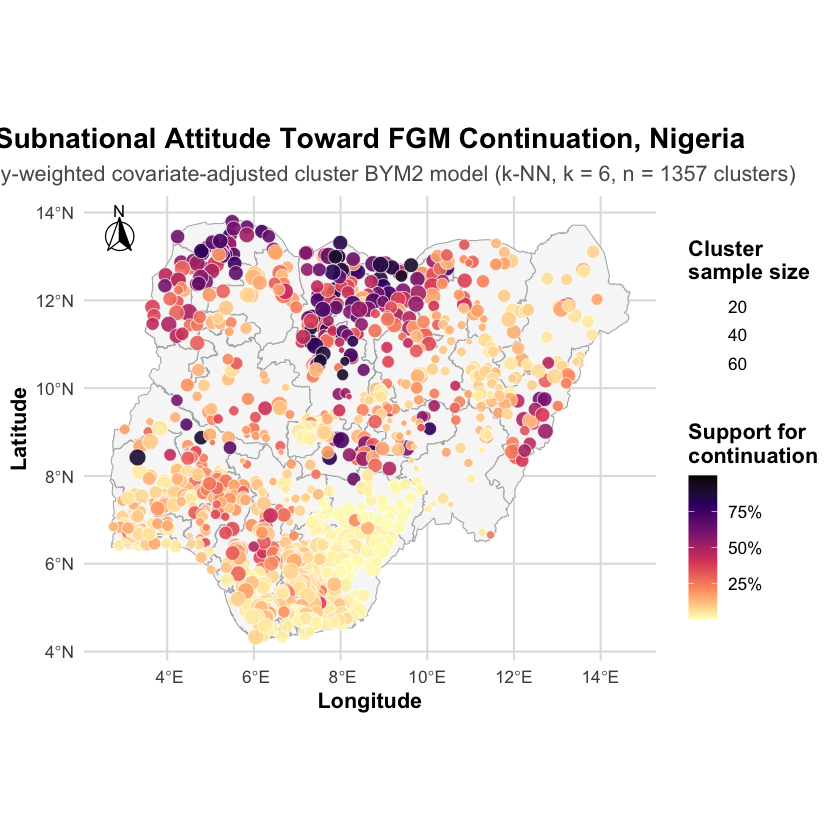

In [27]:
cluster_plot_data <- attitude_clusters |> dplyr::filter(n_unweighted>=minimum_cluster_n_display)
attitude_cluster_map <- ggplot2::ggplot() +
  ggplot2::geom_sf(data=boundaries,fill="grey97",color="grey70",linewidth=.30) +
  ggplot2::geom_point(data=cluster_plot_data,
    ggplot2::aes(x=lon,y=lat,fill=adjusted_support,size=n_unweighted),
    shape=21,color="white",stroke=.30,alpha=.90) +
  ggplot2::scale_fill_viridis_c(name="Support for\ncontinuation",option="magma",direction=-1,
    limits=c(0,1),breaks=c(.25,.50,.75),labels=scales::percent_format(accuracy=1)) +
  ggplot2::scale_size_continuous(name="Cluster\nsample size",range=c(1.6,6),breaks=scales::pretty_breaks(3)) +
  ggspatial::annotation_north_arrow(location="tl",which_north="true",
    style=ggspatial::north_arrow_fancy_orienteering,height=grid::unit(1,"cm"),width=grid::unit(1,"cm")) +
  ggplot2::coord_sf(datum=sf::st_crs(4326)) +
  ggplot2::labs(title=paste("Subnational Attitude Toward FGM Continuation,",country_name),
    subtitle=paste0("Survey-weighted covariate-adjusted cluster BYM2 model (k-NN, k = ",k_neighbours,", n = ",nrow(cluster_plot_data)," clusters)"),
    x="Longitude",y="Latitude") +
  ggplot2::theme_minimal(base_size=13) +
  ggplot2::theme(plot.title=ggplot2::element_text(face="bold",size=17,hjust=.5),
    plot.subtitle=ggplot2::element_text(hjust=.5,color="grey35"),axis.title=ggplot2::element_text(face="bold"),
    legend.title=ggplot2::element_text(face="bold"),panel.grid.major=ggplot2::element_line(color="grey88"))
print(attitude_cluster_map)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_attitude_cluster_adjusted.png")),attitude_cluster_map,width=11,height=9,dpi=300,bg="white")
# end

## 7. Separate adjusted prevalence maps

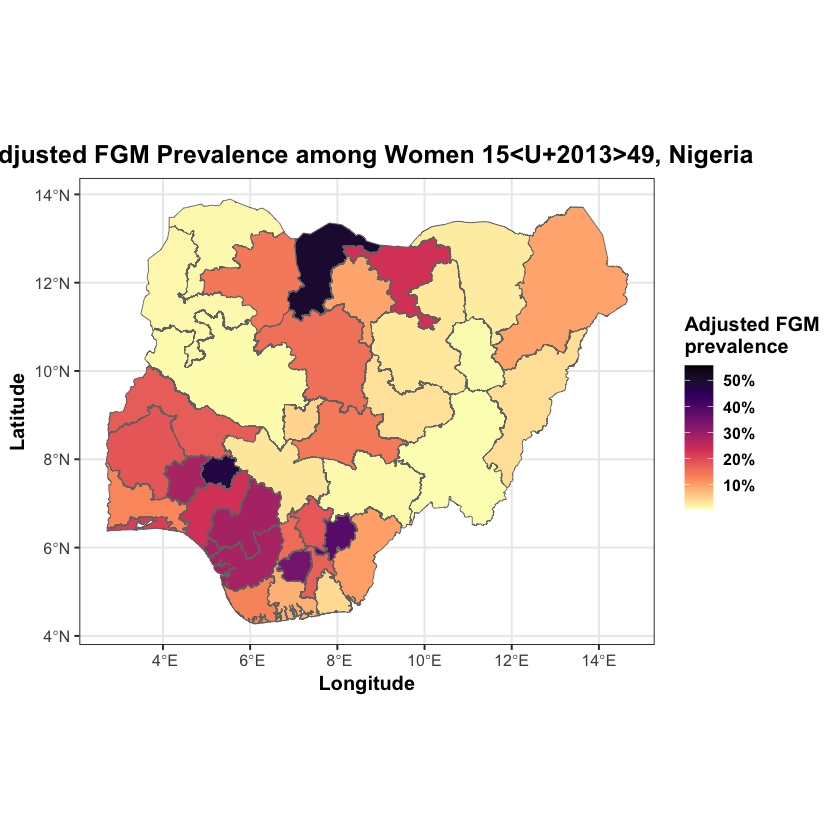

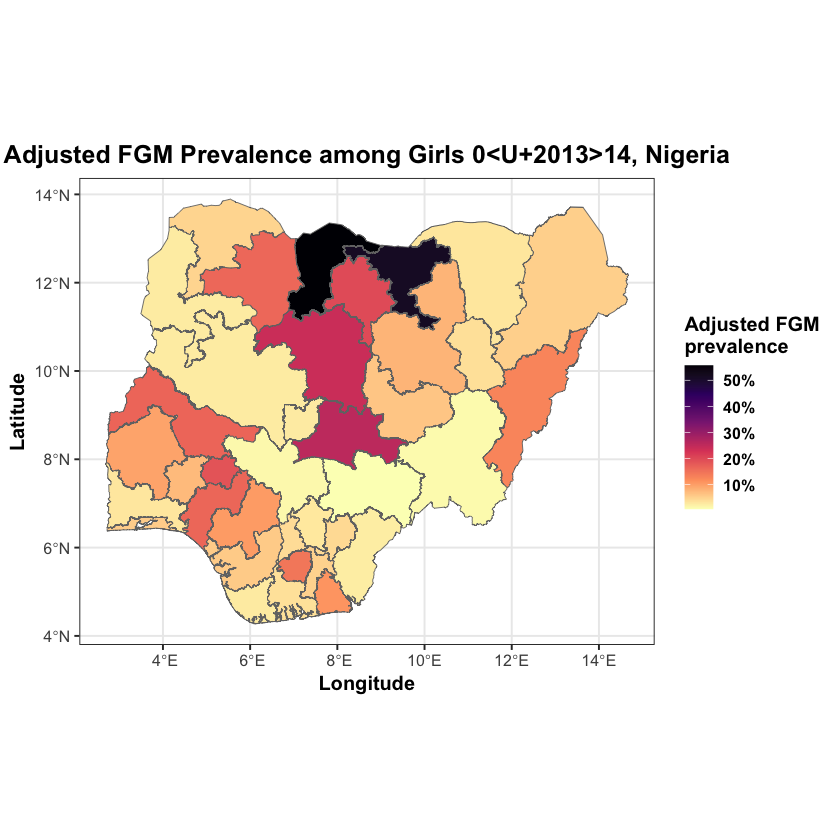

In [28]:
prevalence_long <- dplyr::bind_rows(self_prev,daughter_prev)
prevalence_limits <- range(prevalence_long$prevalence,na.rm=TRUE)
make_prevalence_map <- function(dat,title_text){
  m <- boundaries |> dplyr::left_join(dat,by="region")
  ggplot2::ggplot(m)+ggplot2::geom_sf(ggplot2::aes(fill=prevalence),color="grey45",linewidth=.25)+
    ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,
      limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
    ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=title_text,x="Longitude",y="Latitude")+
    ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=15))
}
women_prevalence_map <- make_prevalence_map(self_prev,paste("Adjusted FGM Prevalence among Women 15–49,",country_name))
daughter_prevalence_map <- make_prevalence_map(daughter_prev,paste("Adjusted FGM Prevalence among Girls 0–14,",country_name))
print(women_prevalence_map);print(daughter_prevalence_map)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_prevalence_women_adjusted.png")),women_prevalence_map,width=9,height=8,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_prevalence_girls_adjusted.png")),daughter_prevalence_map,width=9,height=8,dpi=300,bg="white")
# end

## 8. Separate overlays and combined comparison

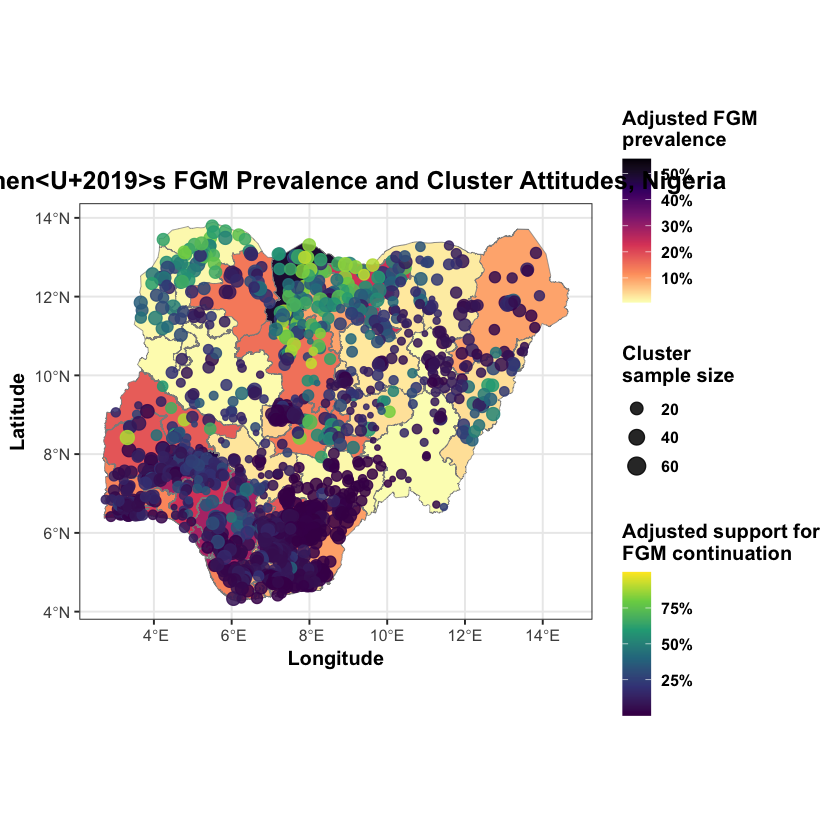

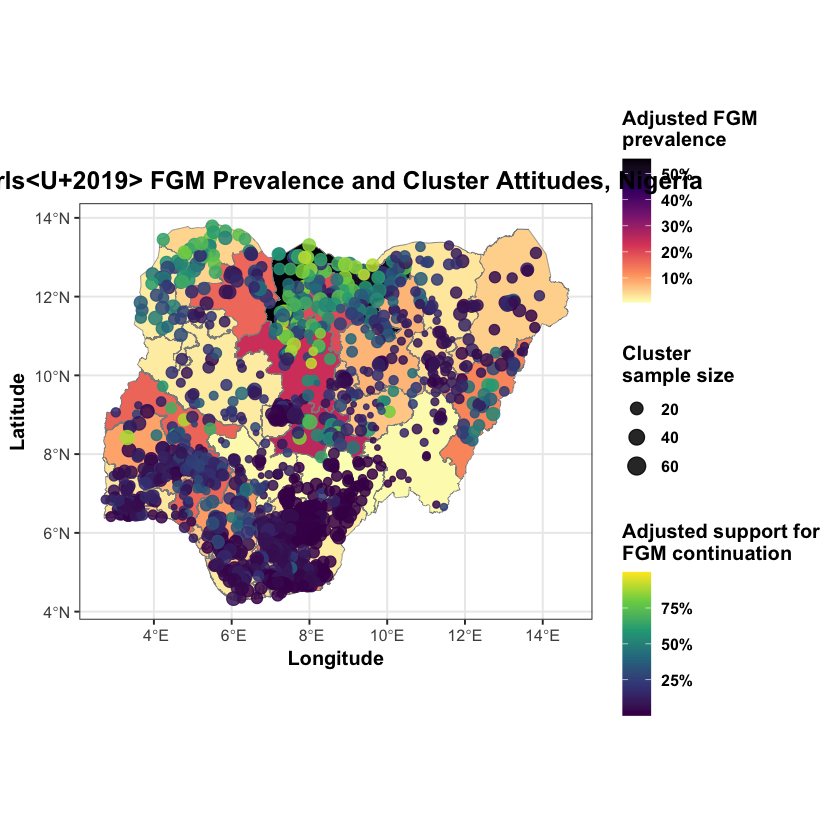

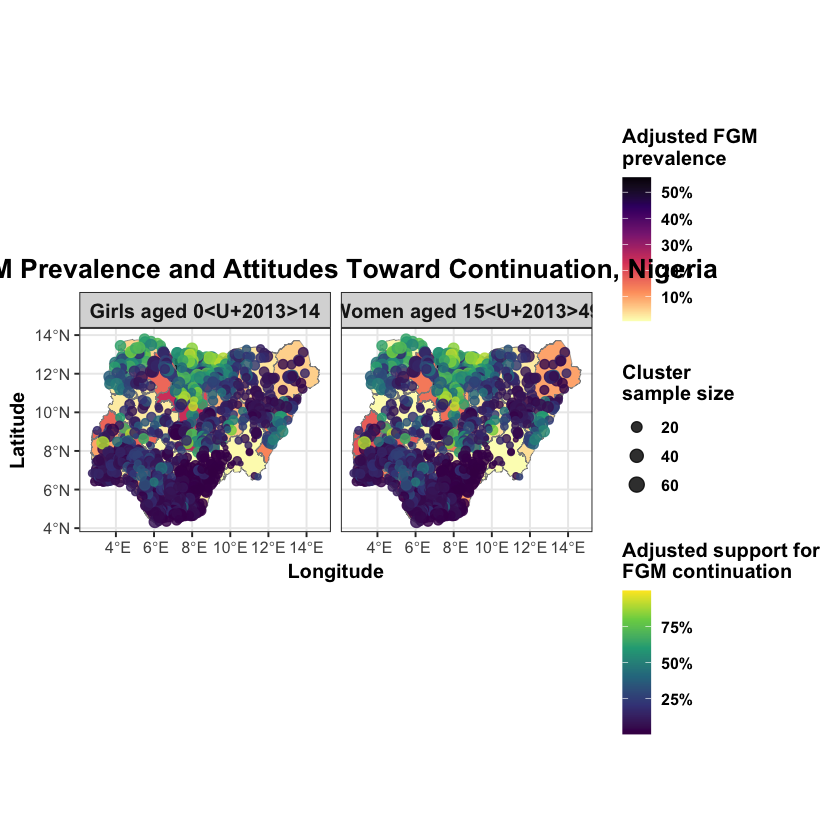

In [29]:
make_overlay <- function(prev,title_text){
  m <- boundaries |> dplyr::left_join(prev,by="region")
  ggplot2::ggplot()+
    ggplot2::geom_sf(data=m,ggplot2::aes(fill=prevalence),color="grey55",linewidth=.2)+
    ggplot2::geom_point(data=cluster_plot_data,ggplot2::aes(x=lon,y=lat,color=adjusted_support,size=n_unweighted),alpha=.85)+
    ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,
      limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
    ggplot2::scale_color_viridis_c(name="Adjusted support for\nFGM continuation",option="viridis",
      limits=c(0,1),breaks=c(.25,.50,.75),labels=scales::percent_format(accuracy=1))+
    ggplot2::scale_size_continuous(name="Cluster\nsample size",range=c(1.2,4.8),breaks=scales::pretty_breaks(3))+
    ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=title_text,x="Longitude",y="Latitude")+
    ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=15))
}
women_overlay <- make_overlay(self_prev,paste("Women’s FGM Prevalence and Cluster Attitudes,",country_name))
girls_overlay <- make_overlay(daughter_prev,paste("Girls’ FGM Prevalence and Cluster Attitudes,",country_name))
print(women_overlay);print(girls_overlay)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_overlay_women_prevalence_attitude.png")),women_overlay,width=11,height=8.5,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_overlay_girls_prevalence_attitude.png")),girls_overlay,width=11,height=8.5,dpi=300,bg="white")

map_data <- dplyr::bind_rows(
  boundaries |> dplyr::mutate(panel="Women aged 15–49") |> dplyr::left_join(self_prev,by=c("region","panel")),
  boundaries |> dplyr::mutate(panel="Girls aged 0–14") |> dplyr::left_join(daughter_prev,by=c("region","panel"))
)
point_data <- dplyr::bind_rows(
  cluster_plot_data |> dplyr::mutate(panel="Women aged 15–49"),
  cluster_plot_data |> dplyr::mutate(panel="Girls aged 0–14")
)
combined_overlay <- ggplot2::ggplot()+
  ggplot2::geom_sf(data=map_data,ggplot2::aes(fill=prevalence),color="grey55",linewidth=.18)+
  ggplot2::geom_point(data=point_data,ggplot2::aes(x=lon,y=lat,color=adjusted_support,size=n_unweighted),alpha=.82)+
  ggplot2::facet_wrap(~panel,ncol=2)+
  ggplot2::scale_fill_viridis_c(name="Adjusted FGM\nprevalence",option="magma",direction=-1,limits=prevalence_limits,labels=scales::percent_format(accuracy=1),oob=scales::squish)+
  ggplot2::scale_color_viridis_c(name="Adjusted support for\nFGM continuation",option="viridis",limits=c(0,1),breaks=c(.25,.5,.75),labels=scales::percent_format(accuracy=1))+
  ggplot2::scale_size_continuous(name="Cluster\nsample size",range=c(1,4),breaks=scales::pretty_breaks(3))+
  ggplot2::coord_sf(datum=sf::st_crs(4326))+ggplot2::labs(title=paste("FGM Prevalence and Attitudes Toward Continuation,",country_name),x="Longitude",y="Latitude")+
  ggplot2::theme_bw(base_size=12)+ggplot2::theme(text=ggplot2::element_text(face="bold"),plot.title=ggplot2::element_text(hjust=.5,size=16),strip.text=ggplot2::element_text(size=12))
print(combined_overlay)
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_combined_prevalence_attitude_overlay.png")),combined_overlay,width=16,height=8.5,dpi=300,bg="white")
ggplot2::ggsave(file.path(output_dir,paste0(country_iso3,"_combined_prevalence_attitude_overlay.pdf")),combined_overlay,width=16,height=8.5,bg="white")
# end

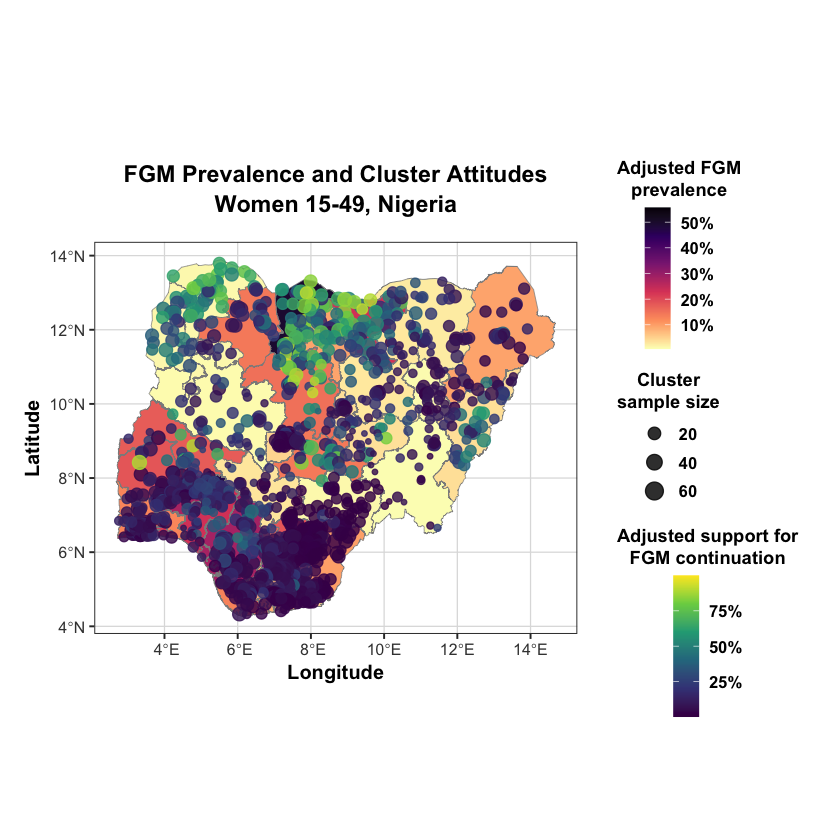

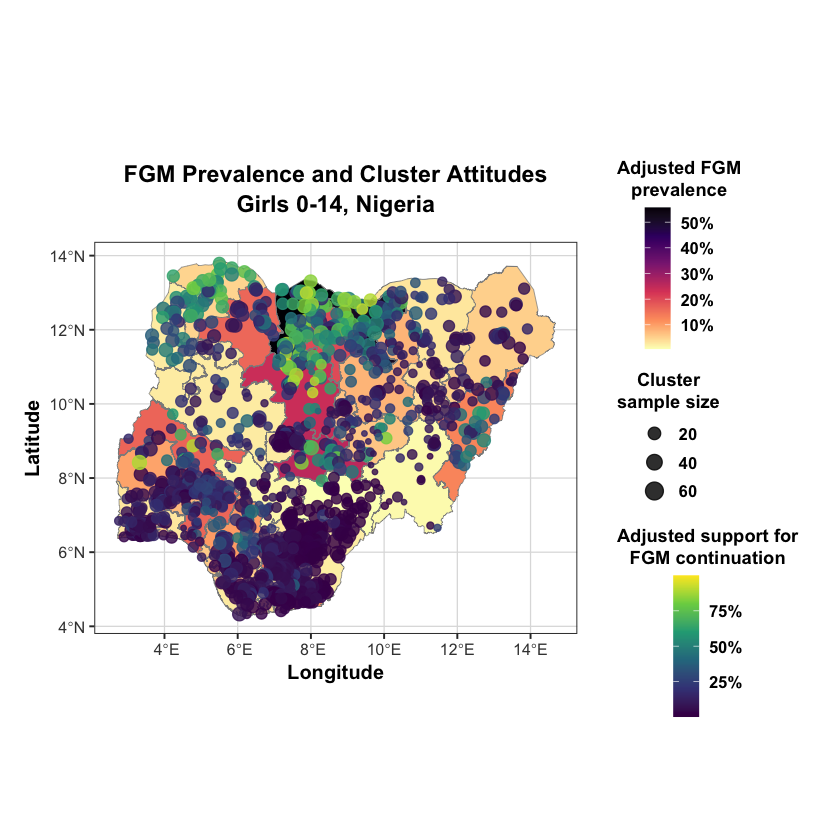

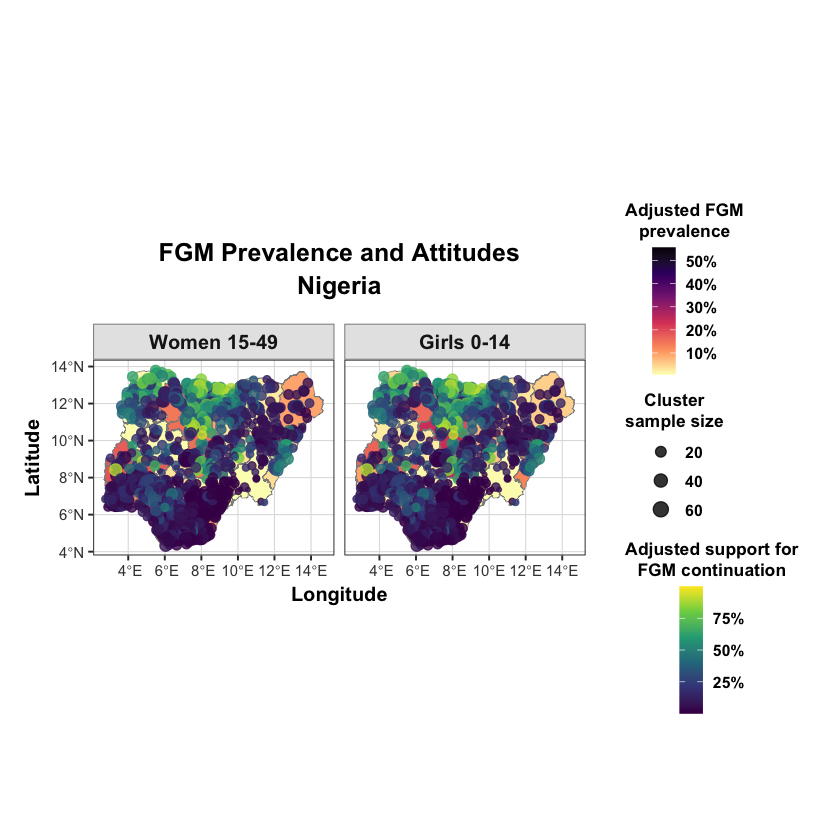

In [31]:
# ============================================================
# 8. Separate overlays and combined comparison
# ============================================================

# Consistent panel labels without special Unicode characters
panel_levels <- c(
  "Women 15-49",
  "Girls 0-14"
)

# ------------------------------------------------------------
# Function for separate prevalence-attitude overlay maps
# ------------------------------------------------------------

make_overlay <- function(
  prevalence_data,
  population_label
) {

  overlay_data <- boundaries |>
    dplyr::left_join(
      prevalence_data |>
        dplyr::select(
          region,
          prevalence
        ),
      by = "region"
    )

  ggplot2::ggplot() +

    # State-level adjusted prevalence
    ggplot2::geom_sf(
      data = overlay_data,
      ggplot2::aes(
        fill = prevalence
      ),
      color = "grey55",
      linewidth = 0.20
    ) +

    # Cluster-level adjusted attitude
    ggplot2::geom_point(
      data = cluster_plot_data,
      ggplot2::aes(
        x = lon,
        y = lat,
        color = adjusted_support,
        size = n_unweighted
      ),
      alpha = 0.82
    ) +

    # Prevalence colour scale
    ggplot2::scale_fill_viridis_c(
      name = "Adjusted FGM\nprevalence",
      option = "magma",
      direction = -1,
      limits = prevalence_limits,
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 1,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.0, "cm"),
        barwidth = grid::unit(0.55, "cm")
      )
    ) +

    # Attitude colour scale
    ggplot2::scale_color_viridis_c(
      name = "Adjusted support for\nFGM continuation",
      option = "viridis",
      limits = c(0, 1),
      breaks = c(
        0.25,
        0.50,
        0.75
      ),
      labels = scales::percent_format(
        accuracy = 1
      ),
      oob = scales::squish,
      guide = ggplot2::guide_colorbar(
        order = 3,
        title.position = "top",
        title.hjust = 0.5,
        barheight = grid::unit(3.0, "cm"),
        barwidth = grid::unit(0.55, "cm")
      )
    ) +

    # Cluster sample-size scale
    ggplot2::scale_size_continuous(
      name = "Cluster\nsample size",
      range = c(1.2, 4.8),
      breaks = scales::pretty_breaks(
        n = 3
      ),
      guide = ggplot2::guide_legend(
        order = 2,
        title.position = "top",
        title.hjust = 0.5
      )
    ) +

    ggplot2::coord_sf(
      datum = sf::st_crs(4326)
    ) +

    # Two-line title
    ggplot2::labs(
      title = paste0(
        "FGM Prevalence and Cluster Attitudes\n",
        population_label,
        ", ",
        country_name
      ),
      x = "Longitude",
      y = "Latitude"
    ) +

    ggplot2::theme_bw(
      base_size = 12
    ) +

    ggplot2::theme(
      text = ggplot2::element_text(
        face = "bold",
        color = "black"
      ),

      plot.title = ggplot2::element_text(
        face = "bold",
        size = 14,
        hjust = 0.5,
        lineheight = 1.1,
        margin = ggplot2::margin(
          b = 15
        )
      ),

      axis.title = ggplot2::element_text(
        face = "bold",
        size = 12
      ),

      axis.text = ggplot2::element_text(
        face = "bold",
        color = "grey25"
      ),

      legend.position = "right",

      legend.title = ggplot2::element_text(
        face = "bold",
        size = 11,
        lineheight = 1.0
      ),

      legend.text = ggplot2::element_text(
        face = "bold",
        size = 10
      ),

      legend.box = "vertical",

      legend.spacing.y = grid::unit(
        0.45,
        "cm"
      ),

      legend.margin = ggplot2::margin(
        l = 12
      ),

      panel.grid.major = ggplot2::element_line(
        color = "grey87",
        linewidth = 0.35
      ),

      panel.grid.minor = ggplot2::element_blank(),

      plot.margin = ggplot2::margin(
        t = 20,
        r = 25,
        b = 15,
        l = 15
      )
    )
}

# ------------------------------------------------------------
# Separate overlay: women aged 15-49
# ------------------------------------------------------------

women_overlay <- make_overlay(
  prevalence_data = self_prev,
  population_label = "Women 15-49"
)

print(
  women_overlay
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.png"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_women_prevalence_attitude.pdf"
    )
  ),
  plot = women_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ------------------------------------------------------------
# Separate overlay: girls aged 0-14
# ------------------------------------------------------------

girls_overlay <- make_overlay(
  prevalence_data = daughter_prev,
  population_label = "Girls 0-14"
)

print(
  girls_overlay
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.png"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_overlay_girls_prevalence_attitude.pdf"
    )
  ),
  plot = girls_overlay,
  width = 13,
  height = 9,
  units = "in",
  bg = "white"
)

# ============================================================
# Prepare the combined two-panel comparison
# ============================================================

women_map_data <- boundaries |>
  dplyr::left_join(
    self_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Women 15-49"
  )

girls_map_data <- boundaries |>
  dplyr::left_join(
    daughter_prev |>
      dplyr::select(
        region,
        prevalence
      ),
    by = "region"
  ) |>
  dplyr::mutate(
    panel = "Girls 0-14"
  )

map_data <- dplyr::bind_rows(
  women_map_data,
  girls_map_data
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# Repeat the same attitude cluster layer in both panels
point_data <- dplyr::bind_rows(
  cluster_plot_data |>
    dplyr::mutate(
      panel = "Women 15-49"
    ),
  cluster_plot_data |>
    dplyr::mutate(
      panel = "Girls 0-14"
    )
) |>
  dplyr::mutate(
    panel = factor(
      panel,
      levels = panel_levels
    )
  )

# ============================================================
# Combined two-panel overlay
# ============================================================

combined_overlay <- ggplot2::ggplot() +

  # State-level adjusted prevalence
  ggplot2::geom_sf(
    data = map_data,
    ggplot2::aes(
      fill = prevalence
    ),
    color = "grey55",
    linewidth = 0.18
  ) +

  # Cluster-level adjusted attitudes
  ggplot2::geom_point(
    data = point_data,
    ggplot2::aes(
      x = lon,
      y = lat,
      color = adjusted_support,
      size = n_unweighted
    ),
    alpha = 0.80
  ) +

  # Women first, girls second
  ggplot2::facet_wrap(
    ~panel,
    ncol = 2
  ) +

  # Shared prevalence scale
  ggplot2::scale_fill_viridis_c(
    name = "Adjusted FGM\nprevalence",
    option = "magma",
    direction = -1,
    limits = prevalence_limits,
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 1,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(2.7, "cm"),
      barwidth = grid::unit(0.50, "cm")
    )
  ) +

  # Shared attitude scale
  ggplot2::scale_color_viridis_c(
    name = "Adjusted support for\nFGM continuation",
    option = "viridis",
    limits = c(0, 1),
    breaks = c(
      0.25,
      0.50,
      0.75
    ),
    labels = scales::percent_format(
      accuracy = 1
    ),
    oob = scales::squish,
    guide = ggplot2::guide_colorbar(
      order = 3,
      title.position = "top",
      title.hjust = 0.5,
      barheight = grid::unit(2.7, "cm"),
      barwidth = grid::unit(0.50, "cm")
    )
  ) +

  # Shared sample-size scale
  ggplot2::scale_size_continuous(
    name = "Cluster\nsample size",
    range = c(1.0, 4.0),
    breaks = scales::pretty_breaks(
      n = 3
    ),
    guide = ggplot2::guide_legend(
      order = 2,
      title.position = "top",
      title.hjust = 0.5
    )
  ) +

  ggplot2::coord_sf(
    datum = sf::st_crs(4326)
  ) +

  # Brief two-line title
  ggplot2::labs(
    title = paste0(
      "FGM Prevalence and Attitudes\n",
      country_name
    ),
    x = "Longitude",
    y = "Latitude"
  ) +

  ggplot2::theme_bw(
    base_size = 12
  ) +

  ggplot2::theme(
    text = ggplot2::element_text(
      face = "bold",
      color = "black"
    ),

    plot.title = ggplot2::element_text(
      face = "bold",
      size = 15,
      hjust = 0.5,
      lineheight = 1.1,
      margin = ggplot2::margin(
        b = 15
      )
    ),

    strip.text = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    strip.background = ggplot2::element_rect(
      fill = "grey90",
      color = "grey50",
      linewidth = 0.5
    ),

    axis.title = ggplot2::element_text(
      face = "bold",
      size = 12
    ),

    axis.text = ggplot2::element_text(
      face = "bold",
      color = "grey25",
      size = 9
    ),

    legend.position = "right",

    legend.title = ggplot2::element_text(
      face = "bold",
      size = 10.5,
      lineheight = 1.0
    ),

    legend.text = ggplot2::element_text(
      face = "bold",
      size = 9.5
    ),

    legend.box = "vertical",

    legend.spacing.y = grid::unit(
      0.35,
      "cm"
    ),

    legend.margin = ggplot2::margin(
      l = 12
    ),

    panel.grid.major = ggplot2::element_line(
      color = "grey87",
      linewidth = 0.30
    ),

    panel.grid.minor = ggplot2::element_blank(),

    plot.margin = ggplot2::margin(
      t = 20,
      r = 25,
      b = 15,
      l = 15
    )
  )

print(
  combined_overlay
)

# ------------------------------------------------------------
# Save combined comparison
# ------------------------------------------------------------

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.png"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  dpi = 300,
  bg = "white"
)

ggplot2::ggsave(
  filename = file.path(
    output_dir,
    paste0(
      country_iso3,
      "_combined_prevalence_attitude_overlay.pdf"
    )
  ),
  plot = combined_overlay,
  width = 17,
  height = 9,
  units = "in",
  bg = "white"
)

## Interpretation

The prevalence polygons and attitude points are related but different outcomes. Polygon colour represents covariate-adjusted FGM prevalence among women or girls. Point colour represents covariate-adjusted support for continuing FGM among interviewed women in that survey cluster, while point size represents the cluster attitude sample. The same point layer and scales are used in both overlays. Spatial coincidence is descriptive, not causal, and DHS point displacement prevents precise local interpretation.

In [30]:
cat("Completed. Outputs saved to:",normalizePath(output_dir,mustWork=FALSE),"\n")
cat("Standalone maps: attitude clusters, women prevalence, girls prevalence.\n")
cat("Overlay maps: women, girls, and combined two-panel comparison.\n")
# end

Completed. Outputs saved to: /Users/jkakai/Desktop/Main/Melaningod/UNFPA/Root/Working Folder/Risk Incidence/03_Outputs/NGA/Prevalence_Attitude_Comparison_v2 


Standalone maps: attitude clusters, women prevalence, girls prevalence.
Overlay maps: women, girls, and combined two-panel comparison.
